# Proyek 4 — Machine Learning: Prediksi Nilai Rumah


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
RANDOM_STATE=42

## 1. Ambil dataset

In [2]:
housing = fetch_california_housing(as_frame=True)
df = housing.frame
print("Bentuk data:", df.shape)
print("Fitur:", housing.feature_names)
print("Target:", housing.target_names)
display(df.head())
display(df.describe().T)

Bentuk data: (20640, 9)
Fitur: ['MedInc', 'HouseAge', 'AveRooms', 'AveBedrms', 'Population', 'AveOccup', 'Latitude', 'Longitude']
Target: ['MedHouseVal']


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422


,count,mean,std,min,25%,50%,75%,max
MedInc,20640.0,3.870671,1.899822,0.499900,2.563400,3.534800,4.743250,15.000100
HouseAge,20640.0,28.639486,12.585558,1.000000,18.000000,29.000000,37.000000,52.000000
AveRooms,20640.0,5.429000,2.474173,0.846154,4.440716,5.229129,6.052381,141.909091
AveBedrms,20640.0,1.096675,0.473911,0.333333,1.006079,1.048780,1.099526,34.066667
Population,20640.0,1425.476744,1132.462122,3.000000,787.000000,1166.000000,1725.000000,35682.000000
AveOccup,20640.0,3.070655,10.386050,0.692308,2.429741,2.818116,3.282261,1243.333333
Latitude,20640.0,35.631861,2.135952,32.540000,33.930000,34.260000,37.710000,41.950000
Longitude,20640.0,-119.569704,2.003532,-124.350000,-121.800000,-118.490000,-118.010000,-114.310000
MedHouseVal,20640.0,2.068558,1.153956,0.149990,1.196000,1.797000,2.647250,5.000010


## 2. Eksplorasi data

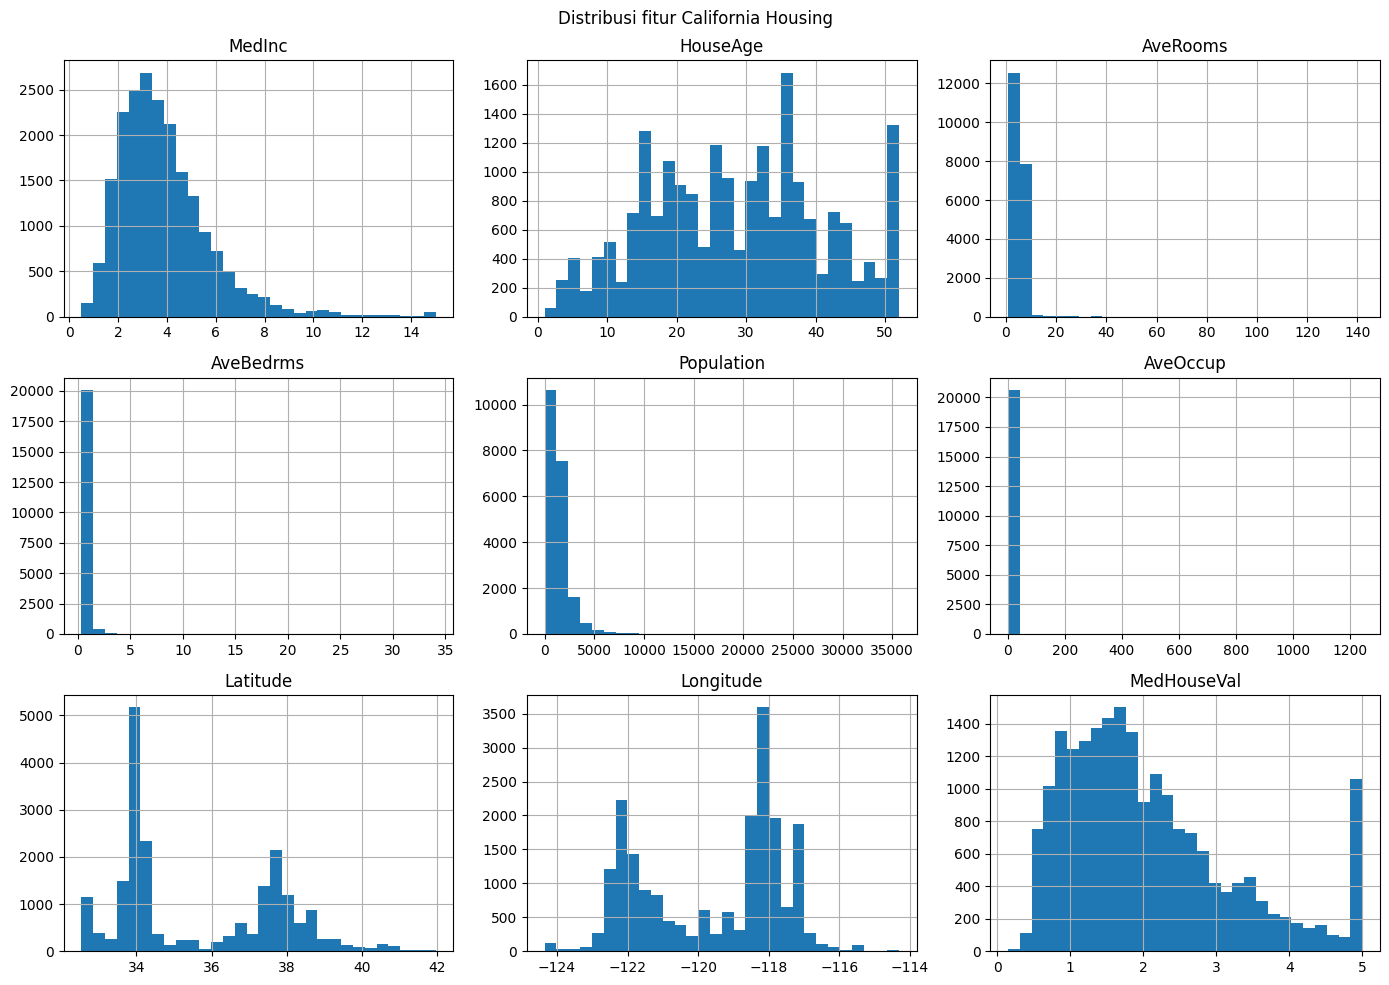

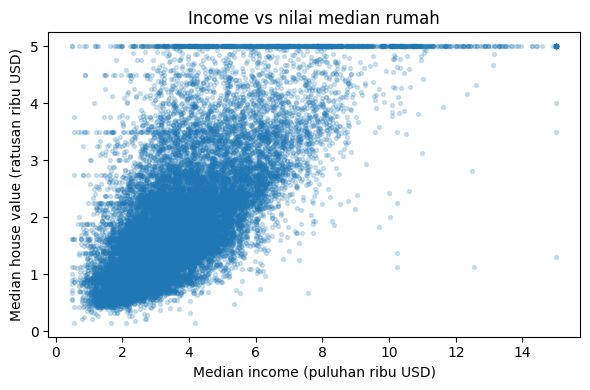

In [3]:
df.hist(figsize=(14,10), bins=30); plt.suptitle("Distribusi fitur California Housing"); plt.tight_layout(); plt.show()
plt.figure(figsize=(6,4)); plt.scatter(df["MedInc"], df["MedHouseVal"], alpha=.2, s=8); plt.xlabel("Median income (puluhan ribu USD)"); plt.ylabel("Median house value (ratusan ribu USD)"); plt.title("Income vs nilai median rumah"); plt.tight_layout(); plt.show()

## 3. Latih dua model dan evaluasi

In [4]:
X=df.drop(columns="MedHouseVal"); y=df["MedHouseVal"]
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=.2,random_state=RANDOM_STATE)
models={
 "Linear Regression":make_pipeline(StandardScaler(),LinearRegression()),
 "Random Forest":RandomForestRegressor(n_estimators=150,random_state=RANDOM_STATE,n_jobs=-1,min_samples_leaf=2)
}
rows=[]; predictions={}
for name, model in models.items():
    model.fit(X_train,y_train); pred=model.predict(X_test); predictions[name]=pred
    rows.append({"Model":name,"MAE":mean_absolute_error(y_test,pred),"RMSE":mean_squared_error(y_test,pred)**0.5,"R2":r2_score(y_test,pred)})
results=pd.DataFrame(rows).sort_values("RMSE")
display(results)

,Model,MAE,RMSE,R2
1,Random Forest,0.326562,0.504420,0.805832
0,Linear Regression,0.533200,0.745581,0.575788


In [6]:
from google.colab import sheets
sheet = sheets.InteractiveSheet(df=results)

https://docs.google.com/spreadsheets/d/1RBMdEvlUdpAp5px-GaXrRwZK9g29pT2-9ohide_unZU/edit#gid=0


## 4. Bandingkan prediksi terbaik

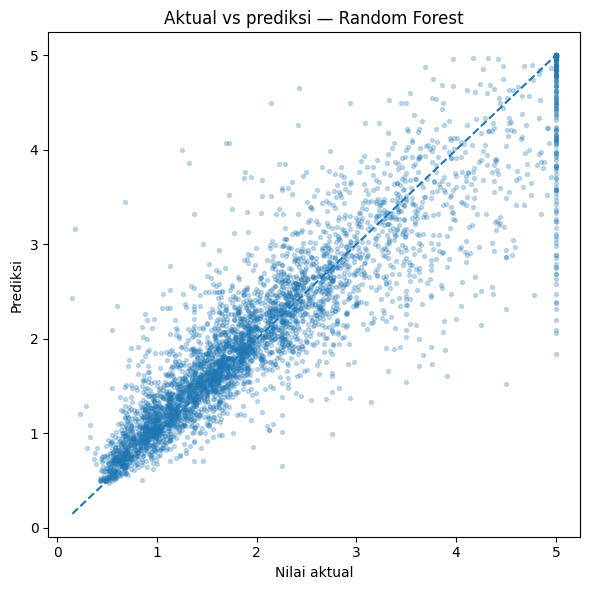

Model dengan RMSE terendah pada split ini: Random Forest


In [7]:
best_name=results.iloc[0]["Model"]; best_pred=predictions[best_name]
plt.figure(figsize=(6,6)); plt.scatter(y_test,best_pred,alpha=.25,s=8)
lims=[min(y_test.min(),best_pred.min()),max(y_test.max(),best_pred.max())]
plt.plot(lims,lims,"--"); plt.xlabel("Nilai aktual"); plt.ylabel("Prediksi"); plt.title(f"Aktual vs prediksi — {best_name}"); plt.tight_layout(); plt.show()
print("Model dengan RMSE terendah pada split ini:",best_name)

## 5. Makna target dan batasan
Target `MedHouseVal` dinyatakan dalam satuan $100.000 (misalnya 2,0 berarti sekitar $200.000). Dataset berasal dari sensus distrik California dan nilai target memiliki batas atas pada data sumber; jangan menganggap model ini langsung berlaku untuk harga rumah Indonesia.